# Installation

`ActiveVisionBenchmark` is a **single Python file**, [`ActiveVisionBenchmark.py`](../ActiveVisionBenchmark.py).
It needs only `numpy`, `torch` and `torchvision`; `matplotlib`, `imageio` and `MotionClouds` are optional.
This notebook explains how to install it and checks that the environment works.

## 1. Create an environment

The commands below are given as text: they are run once in a terminal, not in this notebook.

```bash
python -m venv .venv
source .venv/bin/activate
pip install torch torchvision numpy
```

On Apple silicon, the wheels of PyTorch include the Metal backend (`mps`): no other step is needed.
For the figures, the videos and the notebooks, add the optional dependencies:

```bash
pip install matplotlib imageio imageio-ffmpeg jupyterlab
pip install MotionClouds        # optional: the texture generator of the Motion Clouds package
```

## 2. Get the library

There are three equivalent ways.

* **Copy the file.** Put `ActiveVisionBenchmark.py` next to your script or notebook. Nothing else is needed.
* **With pip, from the repository** (this also installs the dependencies):

  ```bash
  pip install git+https://github.com/laurentperrinet/ActiveVisionBenchmark
  # or, from a clone of the repository:
  pip install -e .
  ```

* **From PyPI**, once the package is published under the name `avb`:

  ```bash
  pip install avb
  ```

In every case the module is imported with

```python
import ActiveVisionBenchmark as avb
```

The notebooks of this repository add the root of the repository to `sys.path`, so that they also work
without any installation.

## 3. Check the installation

In [1]:
import pathlib
import sys

ROOT = pathlib.Path.cwd().parent          # the repository, when the package is not installed
sys.path.insert(0, str(ROOT))

import ActiveVisionBenchmark as avb

In [2]:
import importlib
import platform

print(f"python {platform.python_version()} on {platform.system()} {platform.machine()}")
for name, required in [("numpy", True), ("torch", True), ("torchvision", True),
                       ("matplotlib", False), ("imageio", False), ("imageio_ffmpeg", False), ("MotionClouds", False)]:
    try:
        version = getattr(importlib.import_module(name), "__version__", "installed")
        print(f"{name:15s} {version}")
    except ImportError:
        print(f"{name:15s} NOT INSTALLED" + ("" if required else " (optional)"))
print("library version", avb.__version__)

python 3.14.10 on Darwin arm64
numpy           2.5.4
torch           2.14.1


torchvision     0.29.1
matplotlib      3.11.2
imageio         2.38.1
imageio_ffmpeg  0.7.0
MotionClouds    installed
library version 0.2.0


The compute device is chosen automatically. For a task, the Metal backend (`mps`) is used for images of at
least 192 x 192 pixels and the CPU for smaller ones, which are faster there because the launch overhead of the
Metal kernels dominates.

In [3]:
import torch

print("device by default:", avb.get_device(), "| mps built:", torch.backends.mps.is_built(),
      "| mps available:", torch.backends.mps.is_available())
small = avb.CylinderTask(avb.MotionCloudStimulus(), size=128)
large = avb.CylinderTask(avb.MotionCloudStimulus(), size=256)
print("device of a 128 x 128 task:", small.device, "| of a 256 x 256 task:", large.device)

device by default: mps | mps built: True | mps available: True
device of a 128 x 128 task: cpu | of a 256 x 256 task: mps


A first image: the inner wall of a tunnel. The observer moves along the axis, but its gaze is 6 degrees off it,
so that the focus of expansion is decentred.
The circular mask that blacks out the corners of the image is off by default; set `large.mask = True` to apply it.
It is centred on the image, not on the focus of expansion.

Matplotlib is building the font cache; this may take a moment.


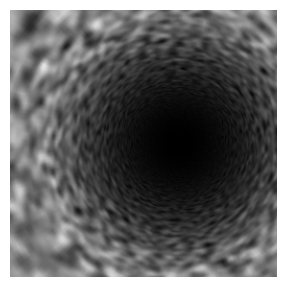

In [4]:
large.mask = False                        # True: a circular mask blacks out the corners of the image
image = large.render(avb.Pose(heading=6.0), seed=0)[0].cpu().numpy()
fig, ax = avb.new_figure(7, 7)
ax.imshow(image, cmap="gray", vmin=0, vmax=1)
ax.axis("off");

A first benchmark, on a handful of trials (the models of the paper are evaluated in notebook 02):

In [5]:
task = avb.HorizontalPlaneTask(avb.MotionCloudStimulus(), size=64, n_steps=6)
bench = avb.Benchmark(task)
results = bench.evaluate(bench.generate_dataset(n_trials=4, seed=0))
for name, res in results.items():
    print(f"{name:7s} RMS error of the heading: {res.rms_error:5.2f} deg")

random  RMS error of the heading:  7.88 deg
flow    RMS error of the heading:  4.08 deg
